In [1]:
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [2]:
# ToTensor() converts the images to tensors and scales pixels from [0, 255] to [0, 1]
transform = transforms.ToTensor()

train_data = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_data = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False, num_workers=2)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print('Training images:', len(train_data))
print('Test images:', len(test_data))

100%|██████████| 170M/170M [44:32<00:00, 63.8kB/s]


Training images: 50000
Test images: 10000


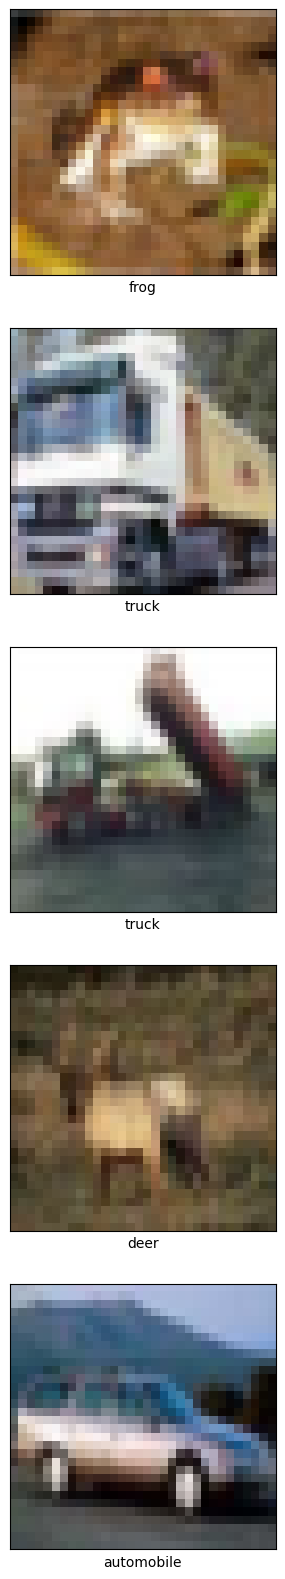

In [3]:
plt.figure(figsize=(10, 20))
for i in range(5):
    image, label = train_data[i]
    plt.subplot(5, 1, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(image.permute(1, 2, 0))
    plt.xlabel(class_names[label])
plt.show()

In [4]:
# No softmax at the end: nn.CrossEntropyLoss applies it internally
model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),

    nn.Flatten(),
    nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
    nn.Linear(64, 10)
).to(device)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(model)
print('Trainable parameters:', count_params(model))

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (7): ReLU()
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=1024, out_features=64, bias=True)
  (10): ReLU()
  (11): Linear(in_features=64, out_features=10, bias=True)
)
Trainable parameters: 122570


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [6]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, optimizer, train_loader, epochs=10, patience=None):
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_loss = float('inf')
    best_weights = None
    wait = 0
    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        val_loss, val_acc = evaluate(model, test_loader)
        history['loss'].append(total_loss / total)
        history['accuracy'].append(correct / total)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        print(f"Epoch {epoch + 1}/{epochs} - loss: {total_loss / total:.4f} - accuracy: {correct / total:.4f}"
              f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

        # Early stopping
        if patience is not None:
            if val_loss < best_loss:
                best_loss = val_loss
                best_weights = copy.deepcopy(model.state_dict())
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    history['time'] = time.time() - start
    return history

In [7]:
history = train_model(model, optimizer, train_loader, epochs=10)

Epoch 1/10 - loss: 1.6281 - accuracy: 0.4021 - val_loss: 1.3633 - val_accuracy: 0.4970
Epoch 2/10 - loss: 1.2948 - accuracy: 0.5328 - val_loss: 1.1857 - val_accuracy: 0.5767
Epoch 3/10 - loss: 1.1559 - accuracy: 0.5915 - val_loss: 1.1083 - val_accuracy: 0.6102
Epoch 4/10 - loss: 1.0575 - accuracy: 0.6265 - val_loss: 1.0592 - val_accuracy: 0.6265
Epoch 5/10 - loss: 0.9863 - accuracy: 0.6529 - val_loss: 1.0069 - val_accuracy: 0.6463
Epoch 6/10 - loss: 0.9301 - accuracy: 0.6724 - val_loss: 0.9664 - val_accuracy: 0.6607
Epoch 7/10 - loss: 0.8841 - accuracy: 0.6895 - val_loss: 0.9802 - val_accuracy: 0.6551
Epoch 8/10 - loss: 0.8431 - accuracy: 0.7047 - val_loss: 0.9470 - val_accuracy: 0.6717
Epoch 9/10 - loss: 0.8136 - accuracy: 0.7144 - val_loss: 0.9272 - val_accuracy: 0.6837
Epoch 10/10 - loss: 0.7835 - accuracy: 0.7237 - val_loss: 0.8653 - val_accuracy: 0.6963


In [8]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test accuracy: {test_acc}")

Test accuracy: 0.6963


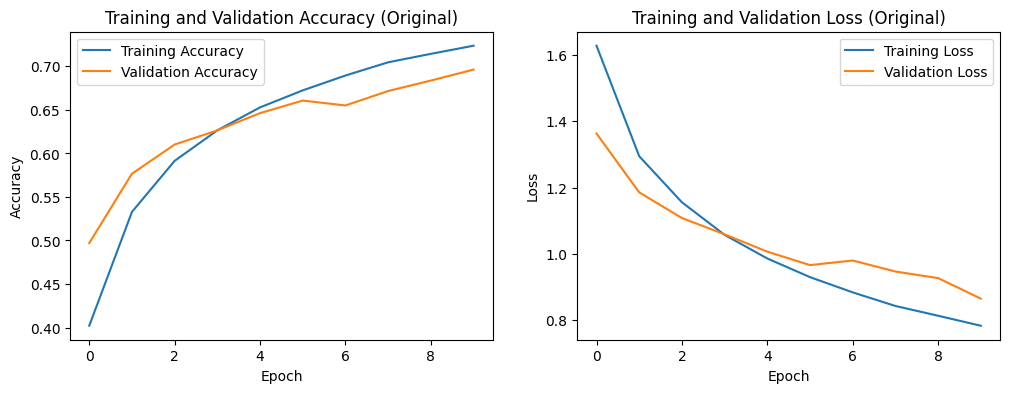

In [9]:
def plot_history(history, title=''):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Training Accuracy')
    plt.plot(history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'Training and Validation Accuracy {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Training Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title(f'Training and Validation Loss {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()


plot_history(history, '(Original)')

In [10]:
test_images = torch.stack([test_data[i][0] for i in range(5)])
test_labels = [test_data[i][1] for i in range(5)]

model.eval()
with torch.no_grad():
    predictions = torch.softmax(model(test_images.to(device)), dim=1).cpu().numpy()

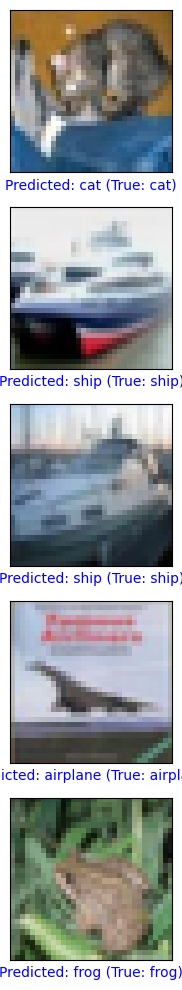

In [11]:
def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.permute(1, 2, 0))

    predicted_label = np.argmax(predictions_array)
    color = 'blue' if predicted_label == true_label else 'red'
    plt.xlabel(f"Predicted: {class_names[predicted_label]} (True: {class_names[true_label]})", color=color)


plt.figure(figsize=(5, 10))
for i in range(5):
    plt.subplot(5, 1, i + 1)
    plot_image(i, predictions, test_labels, test_images)
plt.tight_layout()
plt.show()

## Block 12: Task 1 - Different architectures


Training: Filter size 5x5
Epoch 1/10 - loss: 1.6208 - accuracy: 0.4029 - val_loss: 1.3624 - val_accuracy: 0.5025
Epoch 2/10 - loss: 1.2783 - accuracy: 0.5391 - val_loss: 1.2103 - val_accuracy: 0.5677
Epoch 3/10 - loss: 1.1202 - accuracy: 0.6011 - val_loss: 1.0637 - val_accuracy: 0.6297
Epoch 4/10 - loss: 1.0181 - accuracy: 0.6411 - val_loss: 1.1141 - val_accuracy: 0.6100
Epoch 5/10 - loss: 0.9420 - accuracy: 0.6684 - val_loss: 0.9642 - val_accuracy: 0.6668
Epoch 6/10 - loss: 0.8810 - accuracy: 0.6905 - val_loss: 0.9552 - val_accuracy: 0.6588
Epoch 7/10 - loss: 0.8358 - accuracy: 0.7066 - val_loss: 0.9507 - val_accuracy: 0.6682
Epoch 8/10 - loss: 0.7982 - accuracy: 0.7185 - val_loss: 0.9144 - val_accuracy: 0.6840
Epoch 9/10 - loss: 0.7664 - accuracy: 0.7306 - val_loss: 0.9595 - val_accuracy: 0.6697
Epoch 10/10 - loss: 0.7351 - accuracy: 0.7413 - val_loss: 0.9293 - val_accuracy: 0.6765

Training: More filters (64, 128, 128)
Epoch 1/10 - loss: 1.5397 - accuracy: 0.4364 - val_loss: 1.2476

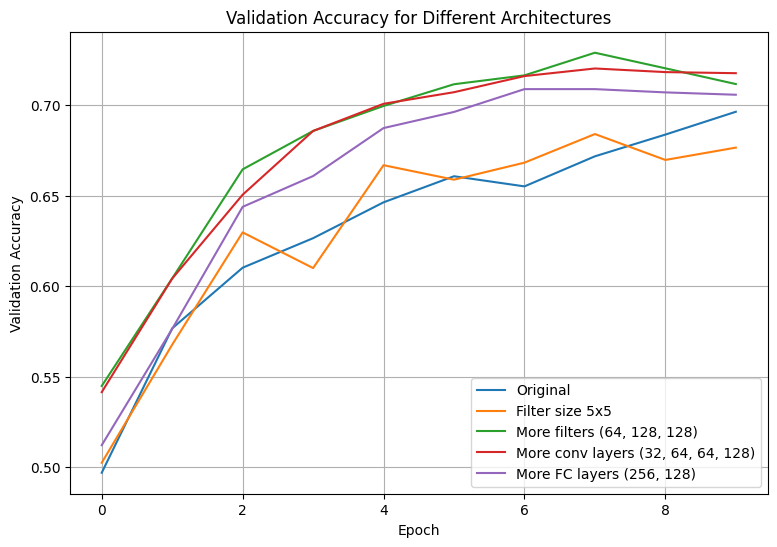

In [12]:
def make_cnn(filters=(32, 64, 64), kernel_size=3, padding=0, dense=(64,)):
    layers = []
    in_channels = 3
    for i, f in enumerate(filters):
        layers += [nn.Conv2d(in_channels, f, kernel_size, padding=padding), nn.ReLU()]
        if i < len(filters) - 1:
            layers.append(nn.MaxPool2d(2))
        in_channels = f
    layers.append(nn.Flatten())

    # Find the flattened size automatically
    with torch.no_grad():
        n_features = nn.Sequential(*layers)(torch.zeros(1, 3, 32, 32)).shape[1]

    for units in dense:
        layers += [nn.Linear(n_features, units), nn.ReLU()]
        n_features = units
    layers.append(nn.Linear(n_features, 10))
    return nn.Sequential(*layers).to(device)


results = [('Original', count_params(model), history['accuracy'][-1], test_acc,
            len(history['loss']), history['time'])]
task1_histories = {'Original': history}

experiments = [
    ('Filter size 5x5', dict(kernel_size=5)),
    ('More filters (64, 128, 128)', dict(filters=(64, 128, 128))),
    ('More conv layers (32, 64, 64, 128)', dict(filters=(32, 64, 64, 128), padding=1)),
    ('More FC layers (256, 128)', dict(dense=(256, 128))),
]

for name, settings in experiments:
    print(f"\nTraining: {name}")
    m = make_cnn(**settings)
    h = train_model(m, optim.Adam(m.parameters(), lr=0.001), train_loader, epochs=10)
    _, acc = evaluate(m, test_loader)
    results.append((name, count_params(m), h['accuracy'][-1], acc, len(h['loss']), h['time']))
    task1_histories[name] = h

plt.figure(figsize=(9, 6))
for name, h in task1_histories.items():
    plt.plot(h['val_accuracy'], label=name)
plt.title('Validation Accuracy for Different Architectures')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

## Block 13: Task 2 & 3 - Improved model (higher accuracy, less overfitting)

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0

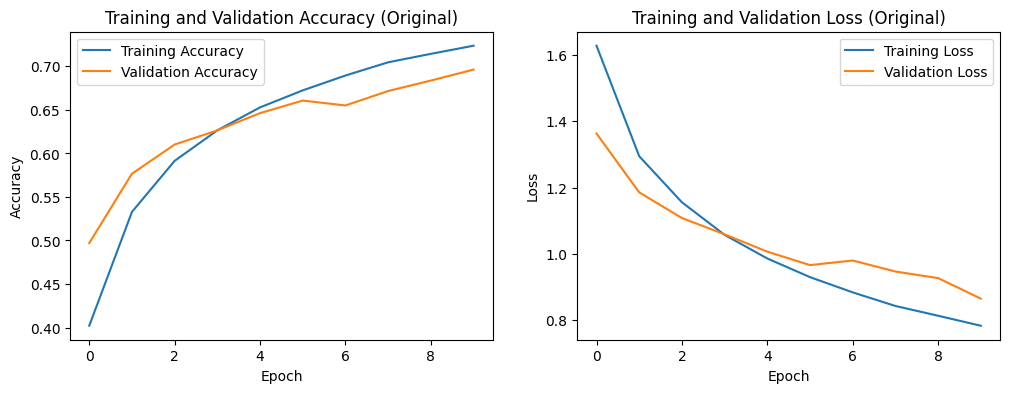

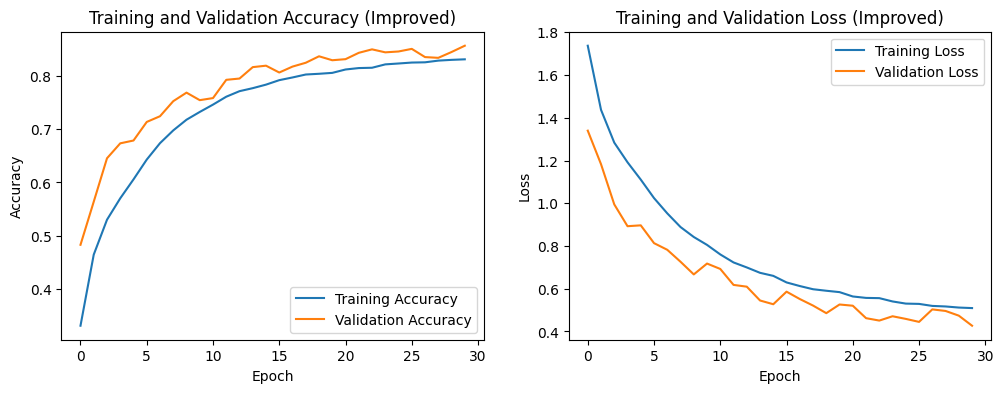

In [13]:
# Data augmentation on the training images only
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])
train_data_aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
train_loader_aug = DataLoader(train_data_aug, batch_size=64, shuffle=True, num_workers=2)


def conv_block(in_channels, out_channels, dropout):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(dropout)
    )


improved_model = nn.Sequential(
    conv_block(3, 32, 0.2),
    conv_block(32, 64, 0.3),
    conv_block(64, 128, 0.4),
    nn.Flatten(),
    nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 10)
).to(device)

print(improved_model)
print('Trainable parameters:', count_params(improved_model))

optimizer = optim.Adam(improved_model.parameters(), lr=0.001, weight_decay=1e-4)
improved_history = train_model(improved_model, optimizer, train_loader_aug, epochs=30, patience=5)

_, improved_acc = evaluate(improved_model, test_loader)
print(f"Improved model test accuracy: {improved_acc}")
results.append(('Improved model', count_params(improved_model), improved_history['accuracy'][-1],
                improved_acc, len(improved_history['loss']), improved_history['time']))

plot_history(history, '(Original)')
plot_history(improved_history, '(Improved)')

## Block 14: Predictions with the improved model

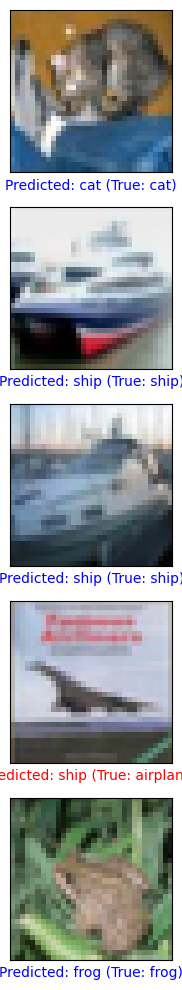

In [14]:
improved_model.eval()
with torch.no_grad():
    predictions = torch.softmax(improved_model(test_images.to(device)), dim=1).cpu().numpy()

plt.figure(figsize=(5, 10))
for i in range(5):
    plt.subplot(5, 1, i + 1)
    plot_image(i, predictions, test_labels, test_images)
plt.tight_layout()
plt.show()

In [15]:
print(f"{'Model':36} {'Params':>9} {'Train acc':>10} {'Test acc':>9} {'Epochs':>7} {'Time (s)':>9}")
for name, params, train_acc, t_acc, epochs, t in results:
    print(f"{name:36} {params:9,} {train_acc:10.4f} {t_acc:9.4f} {epochs:7} {t:9.1f}")

Model                                   Params  Train acc  Test acc  Epochs  Time (s)
Original                               122,570     0.7237    0.6963      10     127.4
Filter size 5x5                        160,970     0.7413    0.6765      10     126.1
More filters (64, 128, 128)            355,018     0.8070    0.7116      10     124.6
More conv layers (32, 64, 64, 128)     261,962     0.8209    0.7176      10     130.7
More FC layers (256, 128)              352,906     0.7971    0.7057      10     129.0
Improved model                         551,466     0.8306    0.8561      30     495.4
